In [3]:
from google.colab import files
upload= files.upload()

Saving social_media_engagement_5000.csv to social_media_engagement_5000 (1).csv


# Social Media Engagement Analytics Using Python

## Task 1: Data Import and Setup

In this section, we import the required Python
libraries and load the social media engagement dataset.

In [5]:
# Import required libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

import warnings
warnings.filterwarnings('ignore')

# Set visualization style
sns.set_style("whitegrid")

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

print("Libraries imported successfully!")

Libraries imported successfully!


In [6]:
# Load the dataset

df = pd.read_csv('social_media_engagement_5000.csv')

# Display first five rows

df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372


In [7]:
# Display last five rows

df.tail()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
4995,59500,44.0,Male,Australia,441541,video,education,16210.0,2013.0,1837.0,6190,42977,25-06-2022,646147,False,mobile,positive,#travel #fun,0.466761
4996,22100,38.0,Other,UAE,677076,reel,education,16924.0,2734.0,1583.0,7764,34196,18-11-2022,584603,False,desktop,negative,#foodie #reels,0.621155
4997,67021,63.0,Female,USA,273595,text,travel,13487.0,NaN,167.0,7466,23680,06-04-2023,483550,False,desktop,positive,#lifestyle #tech,0.679688
4998,29800,13.0,Female,Germany,785644,video,fitness,16894.0,1289.0,1713.0,4991,89013,16-05-2022,183295,False,tablet,positive,#reels #love #fitness,0.223518
4999,73400,54.0,Other,Japan,712252,text,travel,14830.0,503.0,1798.0,3743,14234,04-03-2023,585760,False,desktop,neutral,#foodie #lifestyle #fashion,1.203527


In [8]:
# Check number of rows and columns

print("Dataset Shape:", df.shape)

# Display column names

print("\nColumn Names:")
print(df.columns.tolist())

Dataset Shape: (5000, 19)

Column Names:
['user_id', 'age', 'gender', 'country', 'post_id', 'post_type', 'post_category', 'likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'posted_at', 'follower_count', 'is_verified', 'device_type', 'sentiment', 'hashtags', 'engagement_rate']


In [9]:
# Check dataset information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   object 
 3   country           5000 non-null   object 
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   object 
 6   post_category     5000 non-null   object 
 7   likes             4850 non-null   float64
 8   comments          4850 non-null   float64
 9   shares            4850 non-null   float64
 10  watch_time_sec    5000 non-null   int64  
 11  impression_count  5000 non-null   int64  
 12  posted_at         5000 non-null   object 
 13  follower_count    5000 non-null   int64  
 14  is_verified       5000 non-null   bool   
 15  device_type       5000 non-null   object 
 16  sentiment         4850 non-null   object 


In [10]:
# Check original data types

print(df.dtypes)

user_id               int64
age                 float64
gender               object
country              object
post_id               int64
post_type            object
post_category        object
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at            object
follower_count        int64
is_verified            bool
device_type          object
sentiment            object
hashtags             object
engagement_rate     float64
dtype: object


In [11]:
# Convert posted_at into datetime

df['posted_at'] = pd.to_datetime(
    df['posted_at'],
    format='%d-%m-%Y',
    errors='coerce'
)

# Convert numerical columns

numeric_columns = [
    'age',
    'likes',
    'comments',
    'shares',
    'watch_time_sec',
    'impression_count',
    'follower_count',
    'engagement_rate'
]

for col in numeric_columns:
    df[col] = pd.to_numeric(
        df[col],
        errors='coerce'
    )

print("Data types converted successfully!")

print(df.dtypes)

Data types converted successfully!
user_id                      int64
age                        float64
gender                      object
country                     object
post_id                      int64
post_type                   object
post_category               object
likes                      float64
comments                   float64
shares                     float64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[ns]
follower_count               int64
is_verified                   bool
device_type                 object
sentiment                   object
hashtags                    object
engagement_rate            float64
dtype: object


In [12]:
# Convert likes column into NumPy array

likes_array = df['likes'].dropna().to_numpy()

# Display array

print("Likes Array:")
print(likes_array[:10])

# Basic array operations

print("Total Likes:", np.sum(likes_array))

print("Average Likes:", np.mean(likes_array))

print("Maximum Likes:", np.max(likes_array))

print("Minimum Likes:", np.min(likes_array))

Likes Array:
[ 7011. 11750.  4862.  5350. 12682. 12535. 11703.  9611. 14106.   355.]
Total Likes: 49019162.0
Average Likes: 10107.043711340206
Maximum Likes: 19998.0
Minimum Likes: 10.0


## Task 2: Data Cleaning

In this section, we identify missing values, remove
duplicate records, correct data types, standardize
categorical values and clean feature columns.

In [13]:
# Check missing values in each column

print(df.isnull().sum())

user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64


In [14]:
# Check total missing values

print("Total Missing Values:",
      df.isna().sum().sum())

Total Missing Values: 900


In [15]:
# Fill missing numerical values using median

for col in numeric_columns:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values using mode

categorical_columns = [
    'gender',
    'sentiment'
]

for col in categorical_columns:
    df[col] = df[col].fillna(df[col].mode()[0])

print("Missing values handled successfully!")

Missing values handled successfully!


In [16]:
print(df.isnull().sum())

user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
dtype: int64


In [17]:
# Check duplicate records

print("Duplicate Records:",
      df.duplicated().sum())

# Remove duplicates

df = df.drop_duplicates()

print("Shape after removing duplicates:",
      df.shape)

Duplicate Records: 0
Shape after removing duplicates: (5000, 19)


In [18]:
# Standardize text columns

text_columns = [
    'gender',
    'country',
    'post_type',
    'post_category',
    'device_type',
    'sentiment'
]

for col in text_columns:
    df[col] = (
        df[col]
        .astype(str)
        .str.strip()
        .str.lower()
    )

print("Categorical values standardized!")

Categorical values standardized!


In [19]:
# Standardize sentiment labels

df['sentiment'] = df['sentiment'].replace({
    'pos': 'positive',
    'neg': 'negative',
    'neu': 'neutral'
})

print(df['sentiment'].value_counts())

sentiment
positive    2513
neutral     1527
negative     960
Name: count, dtype: int64


In [20]:
# Check unrealistic negative values

check_columns = [
    'age',
    'likes',
    'comments',
    'shares',
    'watch_time_sec',
    'impression_count',
    'follower_count'
]

for col in check_columns:
    print(col, "Negative values:",
          (df[col] < 0).sum())

age Negative values: 0
likes Negative values: 0
comments Negative values: 0
shares Negative values: 0
watch_time_sec Negative values: 0
impression_count Negative values: 0
follower_count Negative values: 0


In [21]:
# Replace negative values with NaN

for col in check_columns:
    df.loc[df[col] < 0, col] = np.nan

# Fill corrected values using median

for col in check_columns:
    df[col] = df[col].fillna(df[col].median())

print("Unrealistic negative values corrected!")

Unrealistic negative values corrected!


In [22]:
# Count actual hashtags in each post

df['hashtag_count'] = df['hashtags'].apply(
    lambda x: len(
        __import__('re').findall(
            r'#\w+',
            str(x)
        )
    )
)

# Display hashtag count

display(
    df[['hashtags', 'hashtag_count']].head(10)
)

,hashtags,hashtag_count
0,#foodie #travel #love,3
1,#fitness,1
2,#foodie,1
3,#music #foodie #fun,3
4,#travel,1
5,#fitness,1
6,#music,1
7,#travel #music #fitness,3
8,#music #fun #fitness,3
9,#lifestyle #love,2


In [23]:
# Display cleaned dataset

display(df.head())

# Check missing values

print("Missing Values:",
      df.isnull().sum().sum())

# Check duplicates

print("Duplicates:",
      df.duplicated().sum())

# Check shape

print("Final Shape:", df.shape)

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43.0,female,brazil,496713,image,fitness,7011.0,354.0,1157.0,5726.0,44650.0,2022-12-17,81734.0,False,mobile,negative,#foodie #travel #love,0.190862,3
1,10860,33.0,male,brazil,157326,reel,food,11750.0,2606.0,1807.0,5947.0,80216.0,2023-06-02,5963.0,False,mobile,negative,#fitness,0.201493,1
2,86820,32.0,female,uk,109864,text,food,4862.0,344.0,955.0,6946.0,44858.0,2023-05-07,501783.0,False,tablet,positive,#foodie,0.137345,1
3,64886,51.0,other,france,848877,text,fitness,5350.0,1083.0,1049.0,229.0,70455.0,2023-02-12,480212.0,False,mobile,negative,#music #foodie #fun,0.106195,3
4,16265,34.0,other,uk,449706,image,fitness,12682.0,2735.0,1300.0,4798.0,6019.0,2023-05-23,383936.0,False,mobile,negative,#travel,2.777372,1


Missing Values: 0
Duplicates: 0
Final Shape: (5000, 20)


## Task 3: Data Exploration Using Pandas

In this section, we explore the dataset using
Pandas functions and understand the distribution
of social media engagement metrics.

In [24]:
# First five records

display(df.head())

# Last five records

display(df.tail())

# Dataset shape

print("Shape:", df.shape)

# Column names

print("Columns:", df.columns.tolist())

# Data types

print(df.dtypes)

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43.0,female,brazil,496713,image,fitness,7011.0,354.0,1157.0,5726.0,44650.0,2022-12-17,81734.0,False,mobile,negative,#foodie #travel #love,0.190862,3
1,10860,33.0,male,brazil,157326,reel,food,11750.0,2606.0,1807.0,5947.0,80216.0,2023-06-02,5963.0,False,mobile,negative,#fitness,0.201493,1
2,86820,32.0,female,uk,109864,text,food,4862.0,344.0,955.0,6946.0,44858.0,2023-05-07,501783.0,False,tablet,positive,#foodie,0.137345,1
3,64886,51.0,other,france,848877,text,fitness,5350.0,1083.0,1049.0,229.0,70455.0,2023-02-12,480212.0,False,mobile,negative,#music #foodie #fun,0.106195,3
4,16265,34.0,other,uk,449706,image,fitness,12682.0,2735.0,1300.0,4798.0,6019.0,2023-05-23,383936.0,False,mobile,negative,#travel,2.777372,1


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
4995,59500,44.0,male,australia,441541,video,education,16210.0,2013.0,1837.0,6190.0,42977.0,2022-06-25,646147.0,False,mobile,positive,#travel #fun,0.466761,2
4996,22100,38.0,other,uae,677076,reel,education,16924.0,2734.0,1583.0,7764.0,34196.0,2022-11-18,584603.0,False,desktop,negative,#foodie #reels,0.621155,2
4997,67021,63.0,female,usa,273595,text,travel,13487.0,1497.0,167.0,7466.0,23680.0,2023-04-06,483550.0,False,desktop,positive,#lifestyle #tech,0.679688,2
4998,29800,13.0,female,germany,785644,video,fitness,16894.0,1289.0,1713.0,4991.0,89013.0,2022-05-16,183295.0,False,tablet,positive,#reels #love #fitness,0.223518,3
4999,73400,54.0,other,japan,712252,text,travel,14830.0,503.0,1798.0,3743.0,14234.0,2023-03-04,585760.0,False,desktop,neutral,#foodie #lifestyle #fashion,1.203527,3


Shape: (5000, 20)
Columns: ['user_id', 'age', 'gender', 'country', 'post_id', 'post_type', 'post_category', 'likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'posted_at', 'follower_count', 'is_verified', 'device_type', 'sentiment', 'hashtags', 'engagement_rate', 'hashtag_count']
user_id                      int64
age                        float64
gender                      object
country                     object
post_id                      int64
post_type                   object
post_category               object
likes                      float64
comments                   float64
shares                     float64
watch_time_sec             float64
impression_count           float64
posted_at           datetime64[ns]
follower_count             float64
is_verified                   bool
device_type                 object
sentiment                   object
hashtags                    object
engagement_rate            float64
hashtag_count                int64
d

In [25]:
# Generate descriptive statistics

display(df.describe())

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate,hashtag_count
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.0000,5000.000000,5000.000000,5000,5000.000000,5000.000000,5000.000000
mean,54561.890800,38.440400,548042.909000,10106.997400,1502.039800,1002.9106,4014.503200,50013.732800,2022-12-28 13:21:30.240000,393698.224800,0.964356,1.998600
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.0000,0.000000,105.000000,2022-01-01 00:00:00,87.000000,0.006363,1.000000
25%,32309.500000,26.000000,322543.500000,5235.000000,792.000000,511.0000,2017.750000,24988.250000,2022-07-03 18:00:00,194480.000000,0.145781,1.000000
50%,54374.500000,38.000000,548077.500000,10105.500000,1497.000000,1012.0000,4034.500000,49934.500000,2022-12-27 00:00:00,388982.000000,0.253896,2.000000
75%,77180.500000,51.000000,771574.500000,14959.000000,2235.250000,1483.0000,6020.250000,74662.250000,2023-06-28 00:00:00,589744.250000,0.504794,3.000000
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.0000,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,191.504348,3.000000
std,26090.370121,14.687151,260646.957267,5702.293017,856.393312,570.8552,2308.096459,28844.939104,NaN,230927.884535,5.318029,0.812853


In [26]:
# Gender distribution

print("Gender Distribution:")
print(df['gender'].value_counts())

# Post type distribution

print("\nPost Type Distribution:")
print(df['post_type'].value_counts())

# Country distribution

print("\nCountry Distribution:")
print(df['country'].value_counts())

# Sentiment distribution

print("\nSentiment Distribution:")
print(df['sentiment'].value_counts())

Gender Distribution:
gender
male      1849
other     1581
female    1570
Name: count, dtype: int64

Post Type Distribution:
post_type
reel     1283
image    1247
text     1245
video    1225
Name: count, dtype: int64

Country Distribution:
country
india        535
canada       513
brazil       504
uae          503
usa          501
france       496
uk           493
australia    493
germany      490
japan        472
Name: count, dtype: int64

Sentiment Distribution:
sentiment
positive    2513
neutral     1527
negative     960
Name: count, dtype: int64


In [27]:
# Unique post types

print("Unique Post Types:")
print(df['post_type'].unique())

# Number of unique countries

print("Unique Countries:",
      df['country'].nunique())

# Unique categories

print("Unique Categories:")
print(df['post_category'].unique())

Unique Post Types:
['image' 'reel' 'text' 'video']
Unique Countries: 10
Unique Categories:
['fitness' 'food' 'tech' 'travel' 'fashion' 'lifestyle' 'education'
 'music']


In [28]:
# Select numerical columns

correlation = df.select_dtypes(
    include=np.number
).corr()

display(correlation)

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate,hashtag_count
user_id,1.000000,-0.006688,0.020051,0.025811,-0.033395,0.013763,-0.016847,0.015326,0.010124,-0.004282,-0.013692
age,-0.006688,1.000000,-0.013153,-0.036322,-0.007284,0.013871,0.005542,0.013322,-0.024894,0.008039,0.007173
post_id,0.020051,-0.013153,1.000000,0.014526,-0.010540,0.001846,0.018374,-0.007709,-0.002844,0.010139,0.007344
likes,0.025811,-0.036322,0.014526,1.000000,-0.018421,0.004712,0.008710,0.007952,-0.022982,0.093520,-0.002190
comments,-0.033395,-0.007284,-0.010540,-0.018421,1.000000,0.006142,-0.016351,-0.009395,-0.011733,0.000051,-0.015230
shares,0.013763,0.013871,0.001846,0.004712,0.006142,1.000000,0.014658,-0.005204,-0.010783,0.021724,0.013379
watch_time_sec,-0.016847,0.005542,0.018374,0.008710,-0.016351,0.014658,1.000000,-0.004335,0.002761,-0.001148,-0.023301
impression_count,0.015326,0.013322,-0.007709,0.007952,-0.009395,-0.005204,-0.004335,1.000000,-0.015513,-0.232226,-0.002714
follower_count,0.010124,-0.024894,-0.002844,-0.022982,-0.011733,-0.010783,0.002761,-0.015513,1.000000,0.002292,0.008802
engagement_rate,-0.004282,0.008039,0.010139,0.093520,0.000051,0.021724,-0.001148,-0.232226,0.002292,1.000000,0.005319


In [29]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=correlation)

https://docs.google.com/spreadsheets/d/1n7MXXCGSFZtu7XC943_6qzjtV-6WTKg_XRYyzNWVwvw/edit#gid=0


In [31]:
avg_likes = df.groupby(
    'post_type'
)['likes'].mean()

print(avg_likes)

post_type
image    10104.865277
reel     10037.802416
text     10100.148193
video    10188.600000
Name: likes, dtype: float64


In [32]:
country_impressions = df.groupby(
    'country'
)['impression_count'].mean()

print(country_impressions.sort_values(
    ascending=False
))

country
india        52462.386916
france       51727.673387
usa          51263.872255
uk           51119.393509
japan        49616.135593
brazil       49193.174603
uae          48928.413519
canada       48703.150097
germany      48605.406122
australia    48346.383367
Name: impression_count, dtype: float64


In [33]:
sentiment_engagement = df.groupby(
    'sentiment'
)['engagement_rate'].mean()

print(sentiment_engagement)

sentiment
negative    1.038486
neutral     0.991170
positive    0.919744
Name: engagement_rate, dtype: float64


## Task 4: Data Wrangling

In this section, we create new features and
summarize engagement metrics using grouping operations.

In [34]:
# Calculate engagement score

df['engagement_score'] = (
    df['likes'] +
    df['comments'] +
    df['shares']
)

display(
    df[['likes', 'comments',
        'shares', 'engagement_score']].head()
)

,likes,comments,shares,engagement_score
0,7011.0,354.0,1157.0,8522.0
1,11750.0,2606.0,1807.0,16163.0
2,4862.0,344.0,955.0,6161.0
3,5350.0,1083.0,1049.0,7482.0
4,12682.0,2735.0,1300.0,16717.0


In [35]:
# Log transformation

df['log_likes'] = np.log1p(df['likes'])

df['log_comments'] = np.log1p(df['comments'])

df['log_shares'] = np.log1p(df['shares'])

df['log_followers'] = np.log1p(
    df['follower_count']
)

display(df.head())

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count,engagement_score,log_likes,log_comments,log_shares,log_followers
0,25795,43.0,female,brazil,496713,image,fitness,7011.0,354.0,1157.0,5726.0,44650.0,2022-12-17,81734.0,False,mobile,negative,#foodie #travel #love,0.190862,3,8522.0,8.855378,5.872118,7.054450,11.311238
1,10860,33.0,male,brazil,157326,reel,food,11750.0,2606.0,1807.0,5947.0,80216.0,2023-06-02,5963.0,False,mobile,negative,#fitness,0.201493,1,16163.0,9.371694,7.865955,7.499977,8.693497
2,86820,32.0,female,uk,109864,text,food,4862.0,344.0,955.0,6946.0,44858.0,2023-05-07,501783.0,False,tablet,positive,#foodie,0.137345,1,6161.0,8.489411,5.843544,6.862758,13.125925
3,64886,51.0,other,france,848877,text,fitness,5350.0,1083.0,1049.0,229.0,70455.0,2023-02-12,480212.0,False,mobile,negative,#music #foodie #fun,0.106195,3,7482.0,8.585039,6.988413,6.956545,13.081985
4,16265,34.0,other,uk,449706,image,fitness,12682.0,2735.0,1300.0,4798.0,6019.0,2023-05-23,383936.0,False,mobile,negative,#travel,2.777372,1,16717.0,9.448018,7.914252,7.170888,12.858234


In [36]:
category_analysis = df.groupby(
    'post_category'
).agg(
    total_likes=('likes', 'sum'),
    average_likes=('likes', 'mean'),
    average_comments=('comments', 'mean'),
    average_shares=('shares', 'mean'),
    average_engagement=('engagement_rate', 'mean')
)

display(category_analysis)

,total_likes,average_likes,average_comments,average_shares,average_engagement
post_category,,,,,
education,6389813.5,10126.487322,1455.337559,996.445325,0.844222
fashion,5846954.0,9843.356902,1530.540404,982.523569,0.807109
fitness,6692356.5,9914.602222,1501.142222,1042.047407,0.865628
food,6063735.0,10225.522766,1510.876897,1002.801012,1.358628
lifestyle,6179599.5,10180.559308,1467.840198,991.140033,1.091019
music,6480651.0,10205.749606,1558.710236,1024.089764,0.888803
tech,6764095.0,10171.571429,1505.548872,1009.369925,1.160475
travel,6117782.5,10196.304167,1485.948333,968.306667,0.702223


In [37]:
country_analysis = df.groupby(
    'country'
).agg(
    total_posts=('post_id', 'count'),
    average_likes=('likes', 'mean'),
    average_impressions=('impression_count', 'mean'),
    average_engagement=('engagement_rate', 'mean')
)

display(country_analysis)

,total_posts,average_likes,average_impressions,average_engagement
country,,,,
australia,493,10294.124746,48346.383367,1.324339
brazil,504,9886.689484,49193.174603,1.540704
canada,513,10063.066277,48703.150097,0.916659
france,496,10372.876008,51727.673387,1.146402
germany,490,10130.458163,48605.406122,0.759000
india,535,9962.468224,52462.386916,0.655005
japan,472,10088.862288,49616.135593,0.769623
uae,503,10227.487078,48928.413519,1.112352
uk,493,9935.650101,51119.393509,0.850966


In [38]:
sentiment_analysis = df.groupby(
    'sentiment'
).agg(
    average_likes=('likes', 'mean'),
    average_comments=('comments', 'mean'),
    average_shares=('shares', 'mean'),
    average_watch_time=('watch_time_sec', 'mean'),
    average_engagement=('engagement_rate', 'mean')
)

display(sentiment_analysis)

,average_likes,average_comments,average_shares,average_watch_time,average_engagement
sentiment,,,,,
negative,10208.096875,1516.094792,1007.307292,4054.639583,1.038486
neutral,9923.194499,1528.404060,996.565160,4031.823183,0.991170
positive,10180.062077,1480.650617,1005.086749,3988.646240,0.919744


## Task 5: Statistical Analysis

In this section, we calculate mean, median, mode,
standard deviation, variance and percentiles for
the main engagement metrics.

In [39]:
# Select required numerical columns

stats_columns = [
    'likes',
    'comments',
    'shares',
    'watch_time_sec',
    'engagement_rate',
    'follower_count'
]

# Calculate statistical measures

for col in stats_columns:

    print("\nStatistics for:", col)

    print("Mean:", df[col].mean())

    print("Median:", df[col].median())

    print("Mode:", df[col].mode()[0])

    print("Standard Deviation:", df[col].std())

    print("Variance:", df[col].var())

    print("25th Percentile:", df[col].quantile(0.25))

    print("50th Percentile:", df[col].quantile(0.50))

    print("75th Percentile:", df[col].quantile(0.75))

    print("Skewness:", df[col].skew())

    print("Kurtosis:", df[col].kurt())


Statistics for: likes
Mean: 10106.9974
Median: 10105.5
Mode: 10105.5
Standard Deviation: 5702.293017183876
Variance: 32516145.653823998
25th Percentile: 5235.0
50th Percentile: 10105.5
75th Percentile: 14959.0
Skewness: -0.006893616532184278
Kurtosis: -1.1499923609078424

Statistics for: comments
Mean: 1502.0398
Median: 1497.0
Mode: 1497.0
Standard Deviation: 856.3933120458967
Variance: 733409.5049169405
25th Percentile: 792.0
50th Percentile: 1497.0
75th Percentile: 2235.25
Skewness: 0.0038017289479831415
Kurtosis: -1.1443748352968992

Statistics for: shares
Mean: 1002.9106
Median: 1012.0
Mode: 1012.0
Standard Deviation: 570.8551999758862
Variance: 325875.65933950903
25th Percentile: 511.0
50th Percentile: 1012.0
75th Percentile: 1483.0
Skewness: -0.014653583910311461
Kurtosis: -1.1468565626589917

Statistics for: watch_time_sec
Mean: 4014.5032
Median: 4034.5
Mode: 916.0
Standard Deviation: 2308.096459042085
Variance: 5327309.26424261
25th Percentile: 2017.75
50th Percentile: 4034.5


## Task 6: Data Visualization

In this section, we visualize social media engagement
patterns using Matplotlib, Seaborn and Plotly.

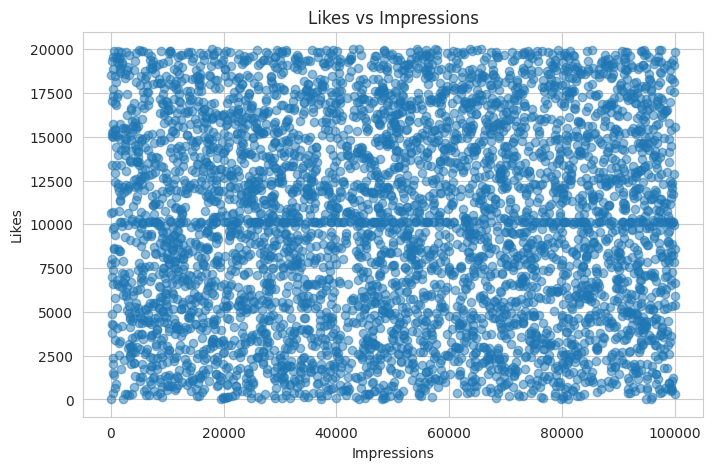

In [40]:
plt.figure(figsize=(8,5))

plt.scatter(
    df['impression_count'],
    df['likes'],
    alpha=0.5
)

plt.xlabel('Impressions')
plt.ylabel('Likes')

plt.title('Likes vs Impressions')

plt.show()

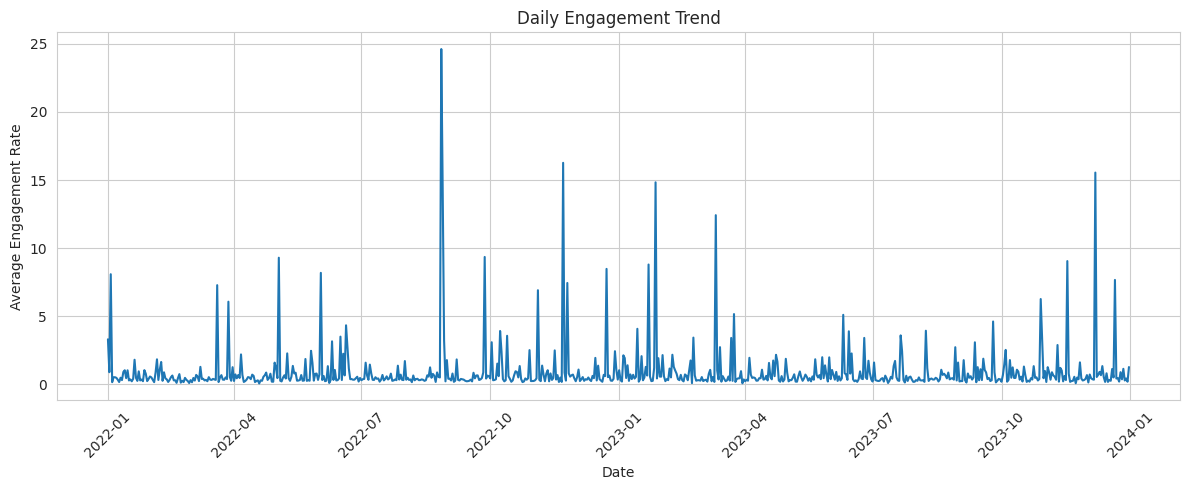

In [41]:
daily_engagement = df.groupby(
    df['posted_at'].dt.date
)['engagement_rate'].mean()

plt.figure(figsize=(12,5))

plt.plot(
    daily_engagement.index,
    daily_engagement.values
)

plt.xlabel('Date')
plt.ylabel('Average Engagement Rate')

plt.title('Daily Engagement Trend')

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

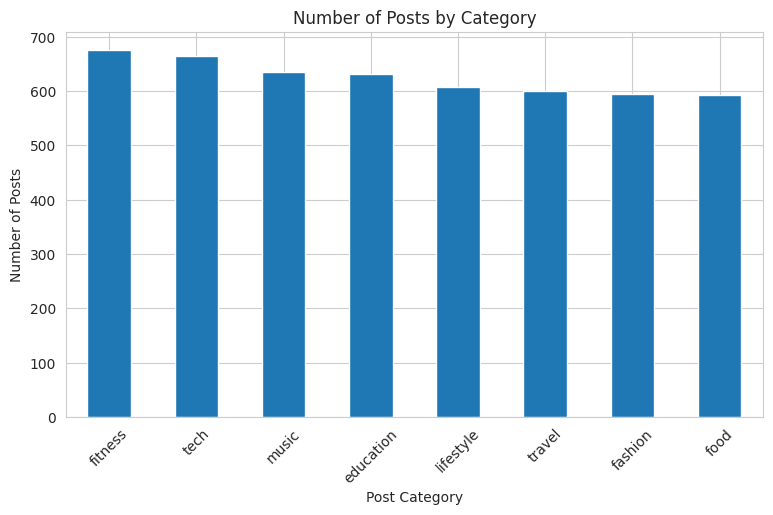

In [42]:
plt.figure(figsize=(9,5))

df['post_category'].value_counts().plot(
    kind='bar'
)

plt.xlabel('Post Category')
plt.ylabel('Number of Posts')

plt.title('Number of Posts by Category')

plt.xticks(rotation=45)

plt.show()

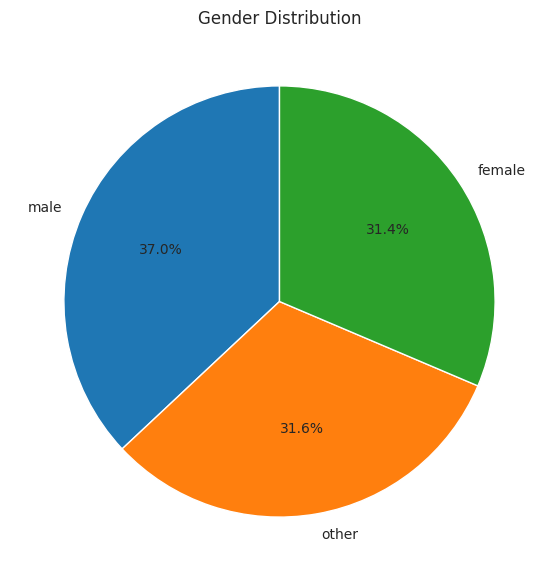

In [43]:
gender_counts = df['gender'].value_counts()

plt.figure(figsize=(7,7))

plt.pie(
    gender_counts,
    labels=gender_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Gender Distribution')

plt.show()

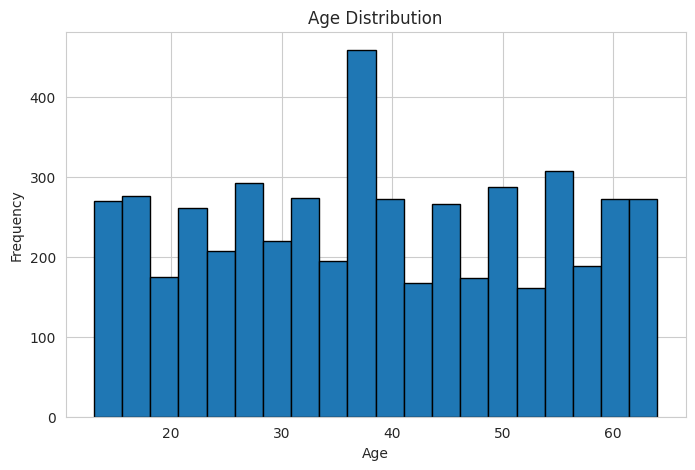

In [44]:
plt.figure(figsize=(8,5))

plt.hist(
    df['age'],
    bins=20,
    edgecolor='black'
)

plt.xlabel('Age')
plt.ylabel('Frequency')

plt.title('Age Distribution')

plt.show()

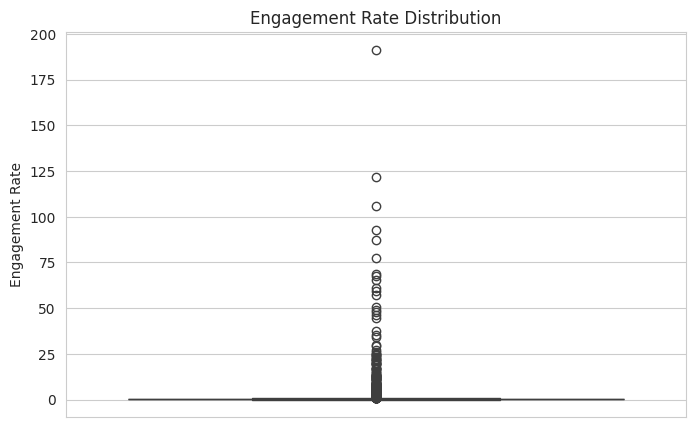

In [45]:
plt.figure(figsize=(8,5))

sns.boxplot(
    y=df['engagement_rate']
)

plt.title('Engagement Rate Distribution')

plt.ylabel('Engagement Rate')

plt.show()

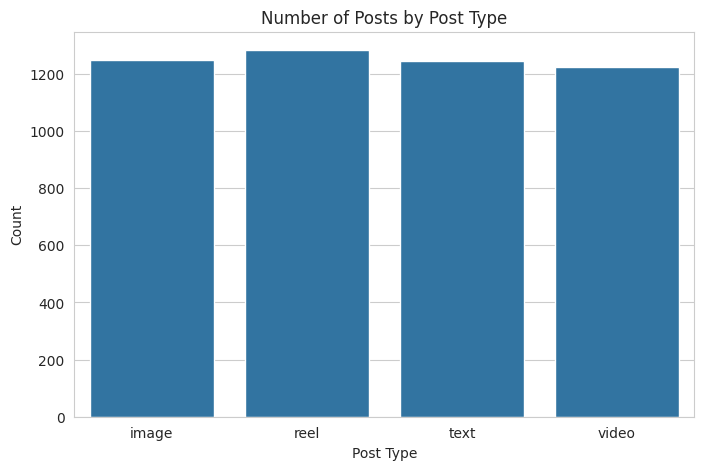

In [46]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x='post_type'
)

plt.xlabel('Post Type')
plt.ylabel('Count')

plt.title('Number of Posts by Post Type')

plt.show()

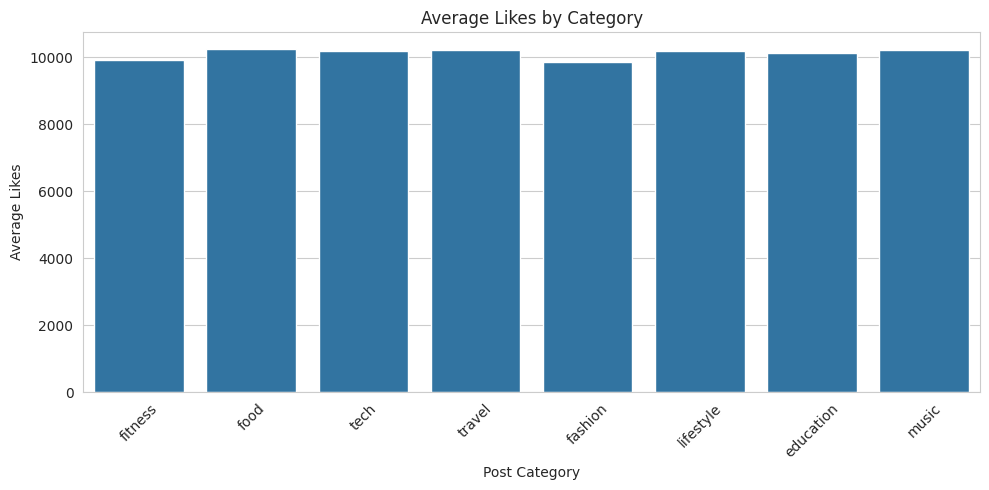

In [47]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=df,
    x='post_category',
    y='likes',
    errorbar=None
)

plt.xlabel('Post Category')
plt.ylabel('Average Likes')

plt.title('Average Likes by Category')

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

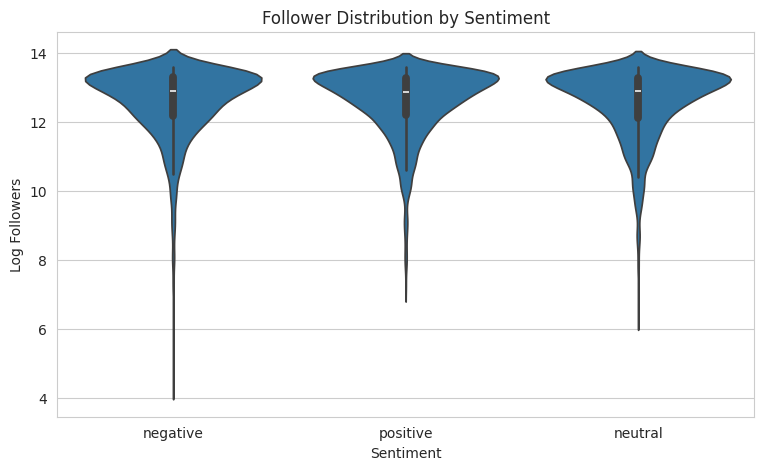

In [48]:
plt.figure(figsize=(9,5))

sns.violinplot(
    data=df,
    x='sentiment',
    y='log_followers'
)

plt.xlabel('Sentiment')
plt.ylabel('Log Followers')

plt.title('Follower Distribution by Sentiment')

plt.show()

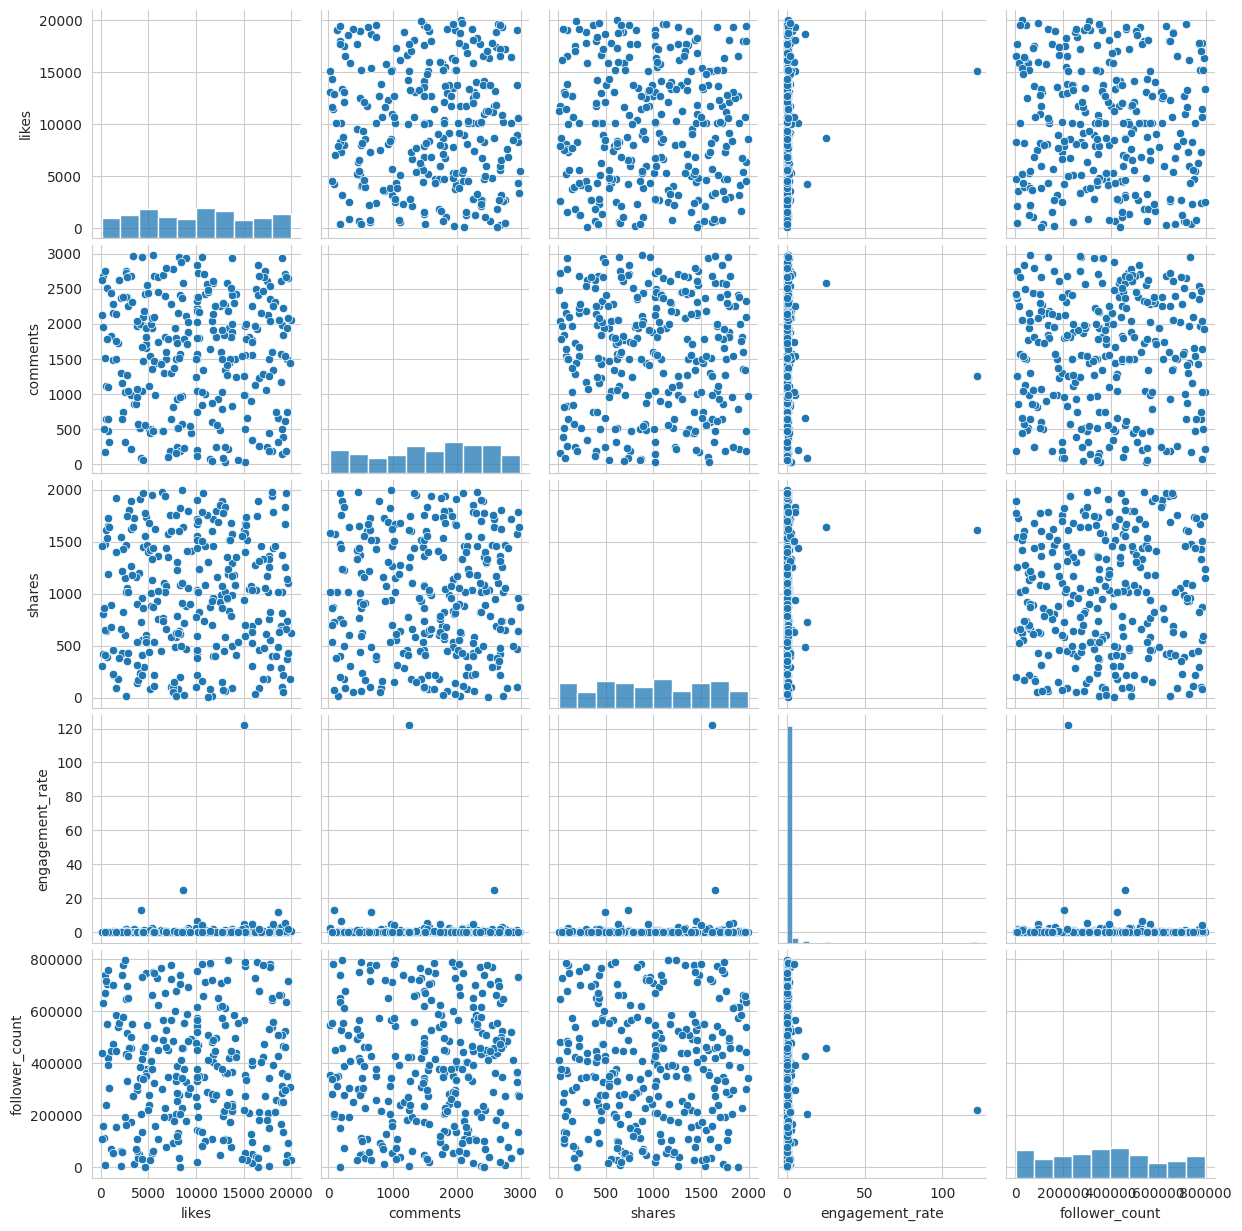

In [49]:
pair_columns = [
    'likes',
    'comments',
    'shares',
    'engagement_rate',
    'follower_count'
]

sns.pairplot(
    df[pair_columns].sample(
        n=min(300, len(df)),
        random_state=42
    )
)

plt.show()

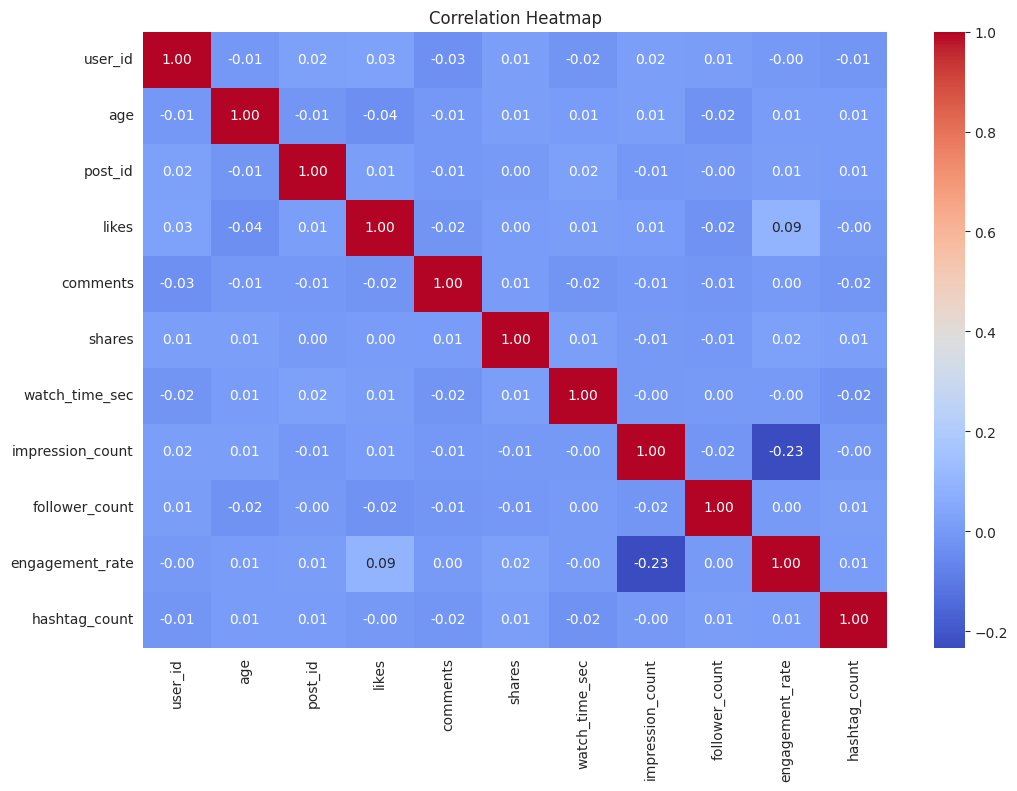

In [50]:
plt.figure(figsize=(12,8))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')

plt.show()

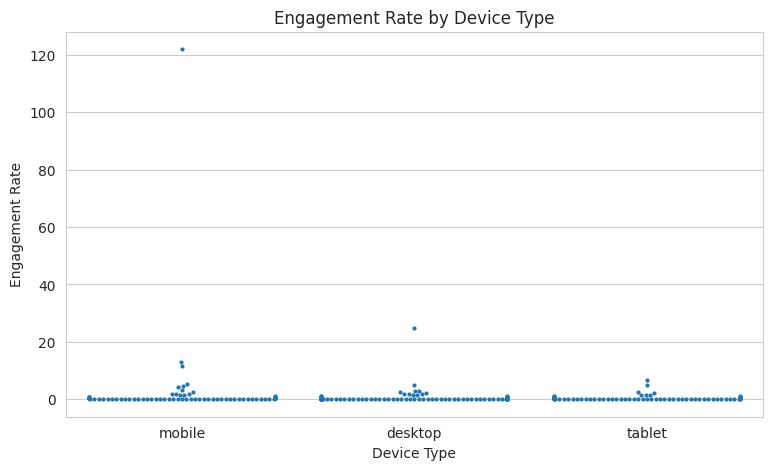

In [51]:
sample_df = df.sample(
    n=min(300, len(df)),
    random_state=42
)

plt.figure(figsize=(9,5))

sns.swarmplot(
    data=sample_df,
    x='device_type',
    y='engagement_rate',
    size=3
)

plt.xlabel('Device Type')
plt.ylabel('Engagement Rate')

plt.title('Engagement Rate by Device Type')

plt.show()

In [52]:
interactive_data = df.groupby(
    'post_type',
    as_index=False
)['engagement_rate'].mean()

fig = px.bar(
    interactive_data,
    x='post_type',
    y='engagement_rate',
    color='post_type',
    title='Average Engagement Rate by Post Type',
    labels={
        'post_type': 'Post Type',
        'engagement_rate': 'Average Engagement Rate'
    }
)

fig.show()

# Final Insights and Business Analysis

This section identifies the best-performing content,
audience trends, country performance, device impact
and sentiment patterns.

In [53]:
post_performance = df.groupby(
    'post_type'
)['engagement_rate'].mean().sort_values(
    ascending=False
)

print(post_performance)

print("\nBest Post Type:")
print(post_performance.idxmax())

post_type
video    1.122365
text     1.064549
image    0.895646
reel     0.783047
Name: engagement_rate, dtype: float64

Best Post Type:
video


In [54]:
category_performance = df.groupby(
    'post_category'
)['engagement_rate'].mean().sort_values(
    ascending=False
)

print(category_performance)

print("\nBest Content Category:")
print(category_performance.idxmax())

post_category
food         1.358628
tech         1.160475
lifestyle    1.091019
music        0.888803
fitness      0.865628
education    0.844222
fashion      0.807109
travel       0.702223
Name: engagement_rate, dtype: float64

Best Content Category:
food


In [55]:
country_performance = df.groupby(
    'country'
)['engagement_rate'].mean().sort_values(
    ascending=False
)

print(country_performance)

print("\nTop Country:")
print(country_performance.idxmax())

country
brazil       1.540704
australia    1.324339
france       1.146402
uae          1.112352
canada       0.916659
uk           0.850966
japan        0.769623
germany      0.759000
india        0.655005
usa          0.576580
Name: engagement_rate, dtype: float64

Top Country:
brazil


age_group
Below 18    0.867038
18-25       1.059536
26-35       0.865316
36-45       0.860741
46-60       1.152669
Above 60    0.801381
Name: engagement_rate, dtype: float64


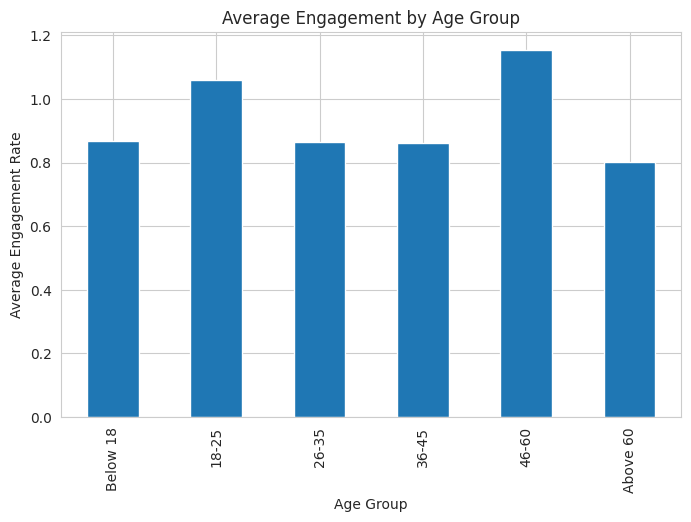

In [56]:
# Create age groups

df['age_group'] = pd.cut(
    df['age'],
    bins=[0, 18, 25, 35, 45, 60, 100],
    labels=[
        'Below 18',
        '18-25',
        '26-35',
        '36-45',
        '46-60',
        'Above 60'
    ]
)

# Calculate average engagement

age_analysis = df.groupby(
    'age_group',
    observed=False
)['engagement_rate'].mean()

print(age_analysis)

# Visualize age analysis

age_analysis.plot(
    kind='bar',
    figsize=(8,5),
    title='Average Engagement by Age Group'
)

plt.xlabel('Age Group')
plt.ylabel('Average Engagement Rate')

plt.show()

In [57]:
verified_analysis = df.groupby(
    'is_verified'
).agg(
    average_likes=('likes', 'mean'),
    average_comments=('comments', 'mean'),
    average_shares=('shares', 'mean'),
    average_engagement=('engagement_rate', 'mean')
)

display(verified_analysis)

,average_likes,average_comments,average_shares,average_engagement
is_verified,,,,
False,10137.201129,1505.511401,1001.599292,0.954744
True,9824.533126,1469.573499,1015.173913,1.054250


device_type
mobile     4087.830760
tablet     3979.736429
desktop    3974.792521
Name: watch_time_sec, dtype: float64


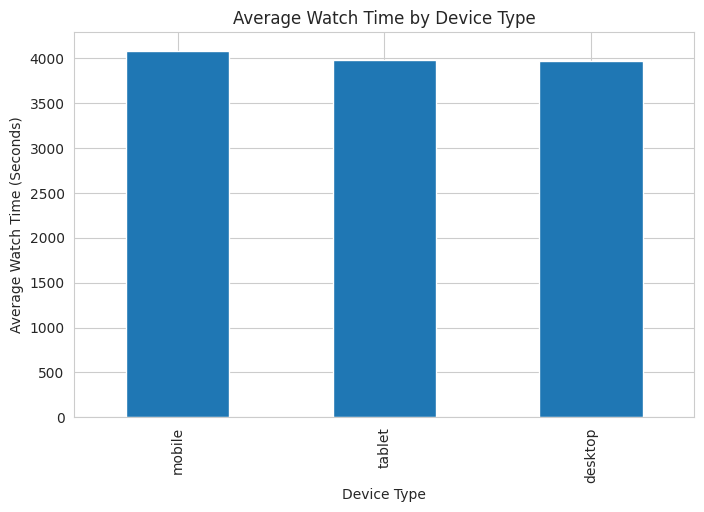

In [58]:
device_analysis = df.groupby(
    'device_type'
)['watch_time_sec'].mean().sort_values(
    ascending=False
)

print(device_analysis)

device_analysis.plot(
    kind='bar',
    figsize=(8,5),
    title='Average Watch Time by Device Type'
)

plt.xlabel('Device Type')
plt.ylabel('Average Watch Time (Seconds)')

plt.show()

In [59]:
sentiment_performance = df.groupby(
    'sentiment'
)['engagement_rate'].mean().sort_values(
    ascending=False
)

print(sentiment_performance)

print("\nBest Performing Sentiment:")
print(sentiment_performance.idxmax())

sentiment
negative    1.038486
neutral     0.991170
positive    0.919744
Name: engagement_rate, dtype: float64

Best Performing Sentiment:
negative


In [60]:
negative_neutral = df[
    df['sentiment'].isin(['negative', 'neutral'])
]

sentiment_comparison = negative_neutral.groupby(
    'sentiment'
).agg(
    average_likes=('likes', 'mean'),
    average_comments=('comments', 'mean'),
    average_shares=('shares', 'mean'),
    average_watch_time=('watch_time_sec', 'mean'),
    average_engagement=('engagement_rate', 'mean')
)

display(sentiment_comparison)

,average_likes,average_comments,average_shares,average_watch_time,average_engagement
sentiment,,,,,
negative,10208.096875,1516.094792,1007.307292,4054.639583,1.038486
neutral,9923.194499,1528.404060,996.565160,4031.823183,0.991170


In [61]:
date_impressions = df.groupby(
    df['posted_at'].dt.date
)['impression_count'].mean()

print("Date with Highest Average Impressions:")

print(date_impressions.idxmax())

print("Average Impressions:")

print(date_impressions.max())

Date with Highest Average Impressions:
2023-12-02
Average Impressions:
98263.5


In [62]:
# Save cleaned dataset

df.to_csv(
    'cleaned_social_media_engagement.csv',
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [63]:
from google.colab import files

files.download('cleaned_social_media_engagement.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Final Project Summary

## Social Media Engagement Analytics Using Python

In [64]:
# Generate final project summary

print("=" * 50)
print("SOCIAL MEDIA ENGAGEMENT ANALYTICS")
print("FINAL PROJECT SUMMARY")
print("=" * 50)

print("\nCONTENT PERFORMANCE")

print("Best Post Type:",
      post_performance.idxmax())

print("Best Category:",
      category_performance.idxmax())

print("\nCOUNTRY PERFORMANCE")

print("Top Country:",
      country_performance.idxmax())

print("\nUSER TRENDS")

print("Best Age Group:",
      age_analysis.idxmax())

print("\nDEVICE ANALYSIS")

print("Best Device:",
      device_analysis.idxmax())

print("\nSENTIMENT ANALYSIS")

print("Best Sentiment:",
      sentiment_performance.idxmax())

print("\nDATASET INFORMATION")

print("Total Records:", len(df))

print("Total Columns:", len(df.columns))

print("Missing Values:",
      df.isnull().sum().sum())

print("Duplicate Records:",
      df.duplicated().sum())

print("\nCONCLUSION")

print("The analysis helps identify social media")
print("engagement patterns across different")
print("content types, countries, age groups,")
print("devices and sentiments.")

print("=" * 50)

SOCIAL MEDIA ENGAGEMENT ANALYTICS
FINAL PROJECT SUMMARY

CONTENT PERFORMANCE
Best Post Type: video
Best Category: food

COUNTRY PERFORMANCE
Top Country: brazil

USER TRENDS
Best Age Group: 46-60

DEVICE ANALYSIS
Best Device: mobile

SENTIMENT ANALYSIS
Best Sentiment: negative

DATASET INFORMATION
Total Records: 5000
Total Columns: 26
Missing Values: 0
Duplicate Records: 0

CONCLUSION
The analysis helps identify social media
engagement patterns across different
content types, countries, age groups,
devices and sentiments.
